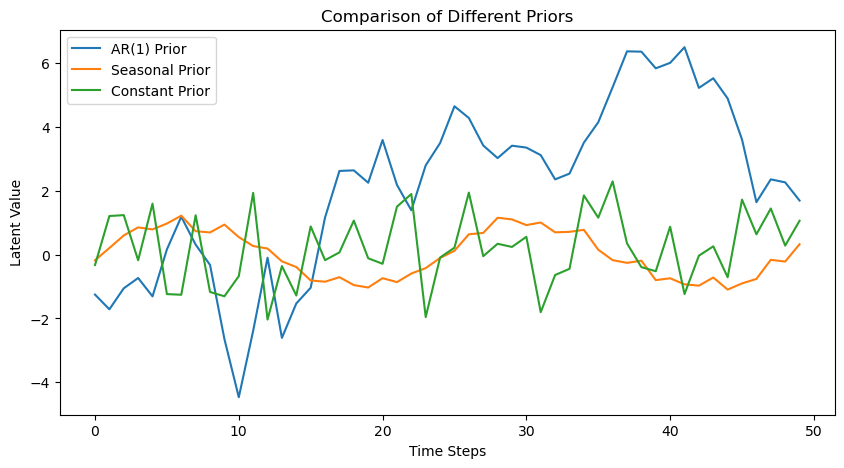

In [18]:
import jax
import jax.numpy as jnp
import flax.nnx as nnx
import matplotlib.pyplot as plt

class p0_AR_fixed(nnx.Module):
    def __init__(self, latent_dim, rngs, phi=0.9, sigma=1.0):
        self.latent_dim = latent_dim
        self.phi = phi
        self.sigma = sigma
        self.initial_state = nnx.Variable(jnp.zeros((1, latent_dim)))
    
    def __call__(self, z_prev):
        prior_mu = self.phi * z_prev
        prior_logvar = 2 * jnp.log(self.sigma) * jnp.ones_like(z_prev)
        prior_logvar = jnp.clip(prior_logvar, -1, 1)
        return prior_mu, prior_logvar
    
    def sample(self, key, z_prev):
        prior_mu, prior_logvar = self(z_prev)
        return jax.random.normal(key, shape=prior_mu.shape) * jnp.exp(0.5 * prior_logvar) + prior_mu

class p0_Seasonal(nnx.Module):
    def __init__(self, latent_dim, rngs, period=24, sigma=0.1):
        self.latent_dim = latent_dim
        self.period = period
        self.sigma = sigma
        self.initial_state = nnx.Variable(jnp.zeros((1, latent_dim)))
    
    def __call__(self, z_prev, t):
        prior_mu = jnp.sin(2 * jnp.pi * t / self.period) * jnp.ones_like(z_prev)
        prior_logvar = 2 * jnp.log(self.sigma) * jnp.ones_like(z_prev)
        prior_logvar = jnp.clip(prior_logvar, -4, -2)  # Tighter clipping range
        return prior_mu, prior_logvar
        
    def sample(self, key, z_prev, t):
        prior_mu, prior_logvar = self(z_prev, t)
        return jax.random.normal(key, shape=prior_mu.shape) * jnp.exp(0.5 * prior_logvar) + prior_mu

class p0_Constant(nnx.Module):
    def __init__(self, latent_dim, rngs, sigma=1.0):
        self.latent_dim = latent_dim
        self.sigma = sigma
        self.initial_state = nnx.Variable(jnp.zeros((1, latent_dim)))
    
    def __call__(self, z_prev):
        prior_mu = jnp.zeros_like(z_prev)
        prior_logvar = 2 * jnp.log(self.sigma) * jnp.ones_like(z_prev)
        prior_logvar = jnp.clip(prior_logvar, -1, 1)
        return prior_mu, prior_logvar
    
    def sample(self, key, z_prev):
        prior_mu, prior_logvar = self(z_prev)
        return jax.random.normal(key, shape=prior_mu.shape) * jnp.exp(0.5 * prior_logvar) + prior_mu

# Visualization
def plot_priors():
    key = jax.random.PRNGKey(0)
    time_steps = 50
    z_prev = jnp.zeros((1, 1))
    
    ar_prior = p0_AR_fixed(1, key)
    seasonal_prior = p0_Seasonal(1, key, period=24)
    constant_prior = p0_Constant(1, key)
    
    ar_samples = []
    seasonal_samples = []
    constant_samples = []
    
    for t in range(time_steps):
        key, subkey = jax.random.split(key)
        z_prev = ar_prior.sample(subkey, z_prev)
        ar_samples.append(z_prev.item())
        
    z_prev = jnp.zeros((1, 1))
    for t in range(time_steps):
        key, subkey = jax.random.split(key)
        z_prev = seasonal_prior.sample(subkey, z_prev, t)
        seasonal_samples.append(z_prev.item())
        
    z_prev = jnp.zeros((1, 1))
    for t in range(time_steps):
        key, subkey = jax.random.split(key)
        z_prev = constant_prior.sample(subkey, z_prev)
        constant_samples.append(z_prev.item())
    
    plt.figure(figsize=(10, 5))
    plt.plot(ar_samples, label='AR(1) Prior')
    plt.plot(seasonal_samples, label='Seasonal Prior')
    plt.plot(constant_samples, label='Constant Prior')
    plt.legend()
    plt.xlabel('Time Steps')
    plt.ylabel('Latent Value')
    plt.title('Comparison of Different Priors')
    plt.show()

# Run the plot function
plot_priors()
